# 3. Modelling

* **How many bikes will be at station X in Y minutes?** Regression, for Y = 10, 30 and 60.
* **Will station X be empty or full in 30 minutes?** Three-class classification.

### Validation
Rows next to each other in time are almost identical, so a random train/test split would leak
the answer. Everything here is split by time:

* **Hold-out test set:** April to June 2026. Never used for any choice, only for the final scores.
* **Model selection:** `TimeSeriesSplit` on the training period (January 2025 to March 2026),
  so each fold trains on the past and validates on the months that follow.

Training uses a 35% random sample of the training rows. Neighbouring 10-minute rows are
near-duplicates, so this costs almost nothing in accuracy and makes each fit several times faster.

In [1]:
import sys
sys.path.insert(0, "..")
import gc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve
from sklearn.model_selection import TimeSeriesSplit

from bikes.features import HORIZONS, NUMERIC_FEATURES
from bikes.models import (FEATURES, HistoricalAverageBaseline, LGBMRegressorModel, LGBMStatusClassifier,
                          PersistenceBaseline, RidgeModel, empty_scores, regression_scores)
from bikes.train import TRAIN_SAMPLE, build_dataset, load_grid, split

sns.set_theme(style="whitegrid")
grid = load_grid()
df = build_dataset(30, grid)
train, test = split(df)
train_s = train.sample(frac=TRAIN_SAMPLE, random_state=42).sort_values("time")
print(f"train {len(train):,} rows (sample {len(train_s):,}), test {len(test):,} rows")
print("test period:", test["time"].min(), "to", test["time"].max())

train 7,225,954 rows (sample 2,529,084), test 1,498,768 rows
test period: 2026-03-31 23:30:00+00:00 to 2026-06-30 23:20:00+00:00


## 3.1 The models
| Model | Idea |
|---|---|
| Persistence | "Nothing changes": the station will have what it has now |
| Historical average | Average for this station, weekday/weekend and time of day. Ignores the current count |
| Ridge regression | Linear model on all numeric features |
| LightGBM | Gradient boosted trees on all features, station as a category. Predicts the *change* in bikes with Huber loss |

Features: current bikes and docks, fill ratio, bikes 10/30/60 minutes ago and the change since,
hour of day (as sine and cosine so midnight wraps round), weekday, weekend and holiday flags,
rain / temperature / wind for the target hour, rain in the previous hour, and the station's
location and identity.

In [2]:
MODELS = {"Persistence": PersistenceBaseline, "Historical average": HistoricalAverageBaseline,
          "Ridge": RidgeModel, "LightGBM": LGBMRegressorModel}

cv_rows = []
for fold, (tr_idx, va_idx) in enumerate(TimeSeriesSplit(n_splits=3).split(train_s)):
    tr, va = train_s.iloc[tr_idx], train_s.iloc[va_idx]
    for name, cls in MODELS.items():
        scores = regression_scores(va["target_bikes"], cls().fit(tr).predict(va))
        cv_rows.append({"fold": fold, "model": name, "valid_from": va["time"].min().date(), **scores})
cv = pd.DataFrame(cv_rows)
cv.pivot(index="model", columns="fold", values="MAE").assign(mean=lambda d: d.mean(axis=1)).round(3)

fold,0,1,2,mean
model,,,,
Historical average,5.548,5.634,5.829,5.670
LightGBM,1.039,1.029,0.900,0.989
Persistence,1.102,1.098,0.922,1.041
Ridge,1.205,1.213,1.052,1.157


## 3.2 Hold-out results for 10, 30 and 60 minutes ahead

In [3]:
results, fitted = [], {}
for horizon in HORIZONS:
    d = df if horizon == 30 else build_dataset(horizon, grid)
    tr, te = split(d)
    tr = tr.sample(frac=TRAIN_SAMPLE, random_state=42)
    for name, cls in MODELS.items():
        model = cls().fit(tr)
        results.append({"horizon_min": horizon, "model": name,
                        **regression_scores(te["target_bikes"], model.predict(te))})
        if horizon == 30:
            fitted[name] = model
    if horizon != 30:
        del d, tr, te
        gc.collect()
results = pd.DataFrame(results)
results.pivot(index="model", columns="horizon_min", values=["MAE", "RMSE", "within_2_bikes"]).round(3)

MAE                 RMSE               within_2_bikes  \
horizon_min            10     30     60     10     30     60             10   
model                                                                         
Historical average  5.418  5.418  5.414  6.902  6.900  6.897          0.230   
LightGBM            0.498  0.995  1.483  1.109  1.977  2.770          0.951   
Persistence         0.474  1.056  1.702  1.171  2.216  3.316          0.966   
Ridge               0.532  1.170  1.874  1.158  2.174  3.223          0.943   

                                  
horizon_min            30     60  
model                             
Historical average  0.230  0.231  
LightGBM            0.861  0.773  
Persistence         0.882  0.788  
Ridge               0.836  0.727

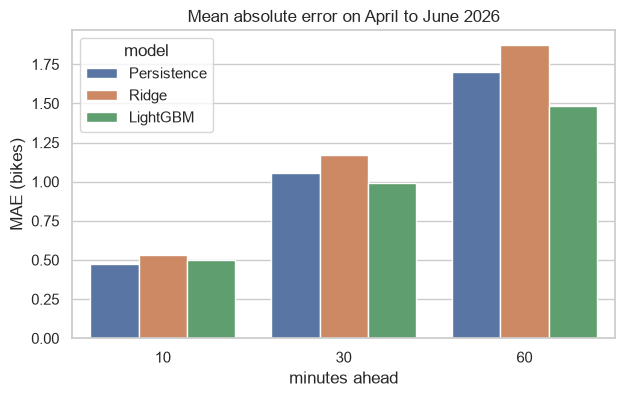

LightGBM error reduction vs persistence: {10: -5.1, 30: 5.8, 60: 12.9} %


In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=results[results["model"] != "Historical average"], x="horizon_min", y="MAE", hue="model", ax=ax)
ax.set(title="Mean absolute error on April to June 2026", xlabel="minutes ahead", ylabel="MAE (bikes)")
plt.show()
lgbm_vs_persist = results.pivot(index="horizon_min", columns="model", values="MAE")
print("LightGBM error reduction vs persistence:",
      ((1 - lgbm_vs_persist["LightGBM"] / lgbm_vs_persist["Persistence"]) * 100).round(1).to_dict(), "%")

## 3.3 Where does the model go wrong?

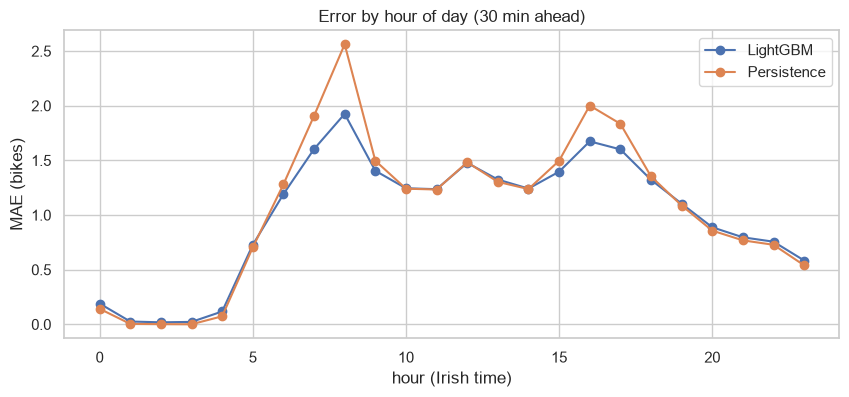

In [5]:
test = test.copy()
test["pred"] = fitted["LightGBM"].predict(test)
test["abs_err"] = (test["pred"] - test["target_bikes"]).abs()
test["persist_err"] = (test["bikes"] - test["target_bikes"]).abs()
test["hour_int"] = test["hour"].astype(int)

fig, ax = plt.subplots(figsize=(10, 4))
test.groupby("hour_int")[["abs_err", "persist_err"]].mean().rename(
    columns={"abs_err": "LightGBM", "persist_err": "Persistence"}).plot(ax=ax, marker="o")
ax.set(title="Error by hour of day (30 min ahead)", xlabel="hour (Irish time)", ylabel="MAE (bikes)")
plt.show()

In [6]:
big_moves = (test["target_bikes"] - test["bikes"]).abs() >= 8
print(f"Slots with a jump of 8+ bikes (mostly rebalancing): {big_moves.mean():.2%} of test rows, "
      f"but {test.loc[big_moves, 'abs_err'].sum() / test['abs_err'].sum():.0%} of the total error")
print(f"MAE without them: {test.loc[~big_moves, 'abs_err'].mean():.3f} bikes")

Slots with a jump of 8+ bikes (mostly rebalancing): 1.63% of test rows, but 16% of the total error
MAE without them: 0.846 bikes


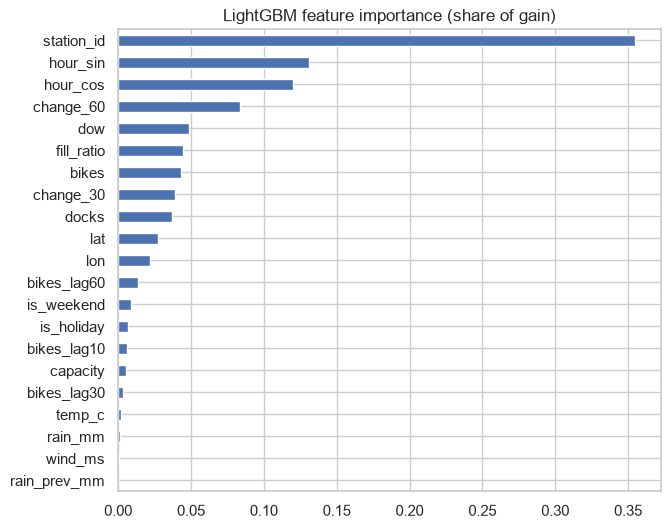

In [7]:
importance = pd.Series(fitted["LightGBM"].model_.booster_.feature_importance("gain"), index=FEATURES)
(importance / importance.sum()).sort_values().plot.barh(figsize=(7, 6), title="LightGBM feature importance (share of gain)")
plt.show()

### Does weather help the prediction?
Retrain LightGBM without the four weather columns and compare.

In [8]:
WEATHER = ["rain_mm", "rain_prev_mm", "temp_c", "wind_ms"]
no_weather = LGBMRegressorModel()
no_weather_feats = [f for f in FEATURES if f not in WEATHER]
import lightgbm as lgb
m = lgb.LGBMRegressor(**no_weather.params).fit(train_s[no_weather_feats], train_s["target_bikes"] - train_s["bikes"])
pred_nw = np.clip(test["bikes"] + m.predict(test[no_weather_feats]), 0, test["bikes"] + test["docks"])
pd.DataFrame({"with weather": regression_scores(test["target_bikes"], test["pred"]),
              "without weather": regression_scores(test["target_bikes"], pred_nw)}).round(4)

,with weather,without weather
MAE,0.9948,0.9942
RMSE,1.9769,1.9766
within_2_bikes,0.8612,0.8612


## 3.4 Will the station be empty or full in 30 minutes?
Classes: **empty** (0 bikes), **OK**, **full** (0 free docks). Empty and full are the minority
classes, so accuracy would look good for a model that always says "OK". I report precision,
recall and the area under the precision-recall curve for the empty class, and compare with the
baseline "it will be empty if it is empty now".

In [9]:
print("class balance in test:", test["target_status"].value_counts(normalize=True).round(3).rename({0: "empty", 1: "OK", 2: "full"}).to_dict())
clf = LGBMStatusClassifier().fit(train_s)
proba = clf.predict_proba(test)
pd.DataFrame({
    "LightGBM, empty": empty_scores(test["target_empty"], proba[:, 0]),
    "Baseline (empty now), empty": empty_scores(test["target_empty"], (test["bikes"] == 0).astype(float)),
    "LightGBM, full": empty_scores(test["target_full"], proba[:, 2]),
    "Baseline (full now), full": empty_scores(test["target_full"], (test["docks"] == 0).astype(float)),
}).T.round(3)

class balance in test: {'OK': 0.857, 'empty': 0.107, 'full': 0.036}


,precision,recall,F1,PR_AUC
"LightGBM, empty",0.820,0.759,0.789,0.882
"Baseline (empty now), empty",0.779,0.779,0.779,0.631
"LightGBM, full",0.790,0.596,0.679,0.798
"Baseline (full now), full",0.705,0.705,0.705,0.508


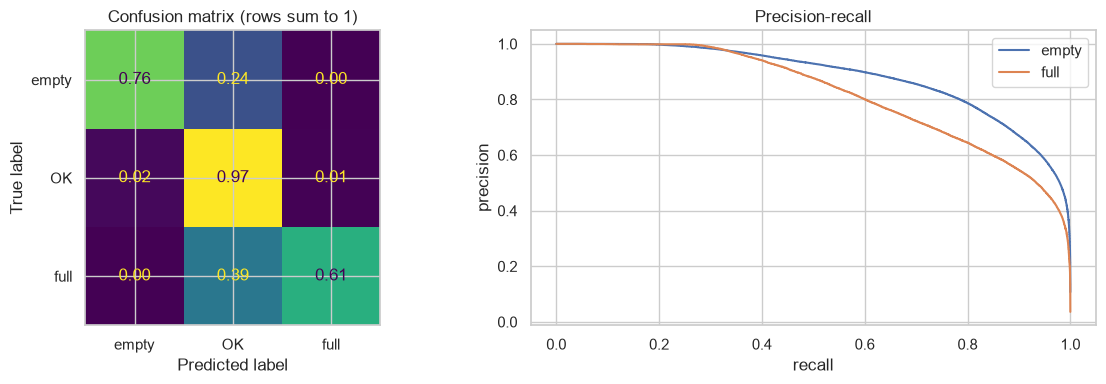

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(test["target_status"], proba.argmax(axis=1), normalize="true",
                                        display_labels=["empty", "OK", "full"], ax=axes[0], colorbar=False,
                                        values_format=".2f")
axes[0].set_title("Confusion matrix (rows sum to 1)")
for col, label in [(0, "empty"), (2, "full")]:
    p, r, _ = precision_recall_curve(test["target_status"] == col, proba[:, col])
    axes[1].plot(r, p, label=label)
axes[1].set(title="Precision-recall", xlabel="recall", ylabel="precision")
axes[1].legend()
plt.tight_layout()
plt.show()

### The cases that matter: stations that are *not* empty now
A user mostly cares about a station that has bikes now but will run out before they get there.
The baseline can never catch those (it only says "empty" when it already is).

In [11]:
not_empty_now = test["bikes"] > 0
becomes_empty = not_empty_now & (test["target_empty"] == 1)
print(f"{becomes_empty.sum():,} test rows where a station with bikes runs out within 30 minutes")
print(empty_scores(test.loc[not_empty_now, "target_empty"], proba[not_empty_now.to_numpy(), 0]))

35,501 test rows where a station with bikes runs out within 30 minutes


{'precision': 0.5778137651821862, 'recall': 0.10050421114898171, 'F1': 0.171225645455418, 'PR_AUC': 0.37822184522525626}


## 3.5 Conclusions (draft)

**How many bikes in Y minutes?** (hold-out, April to June 2026, MAE in bikes)

| | 10 min | 30 min | 60 min |
|---|---|---|---|
| Persistence | **0.47** | 1.06 | 1.70 |
| Historical average | 5.42 | 5.42 | 5.41 |
| Ridge | 0.53 | 1.17 | 1.87 |
| LightGBM | 0.50 | **0.99** | **1.48** |

* "Nothing changes" is a very strong baseline. At 10 minutes nothing beats it on MAE. LightGBM
  has the lower RMSE there (it avoids the big misses) but is slightly worse on typical error.
* The further ahead, the more the model helps: **6% lower error than persistence at 30 minutes,
  13% at 60 minutes**. This matches the TimeSeriesSplit folds on the training period, so it is
  not a lucky test set.
* The historical average alone is far worse (about 5.4 bikes off). The daily routine tells you
  the *shape* of a station's day, but not its level on a given day, which depends on rebalancing
  and on what happened earlier.
* Rebalancing jumps are 1.6% of test rows but 16% of all error. Without them MAE at 30 minutes
  is 0.85 bikes.
* **Weather adds nothing** to the 30-minute prediction (identical scores with and without it).
  Rain clearly reduces usage overall (notebook 2), but over 30 minutes the current count and
  recent trend already carry that information.

**Will it be empty or full in 30 minutes?**

* LightGBM beats the "same as now" baseline on PR-AUC for both empty (0.88 vs 0.63) and full
  (0.80 vs 0.51), and has better precision.
* The hard and useful case is a station that has bikes now but runs out within 30 minutes. That
  happens in under 3% of such rows. At the default 0.5 threshold the model catches only 10% of
  them (precision 58%). PR-AUC there is 0.38, far above the base rate, so a lower threshold
  would trade precision for recall. Choosing that threshold is next.

**Next for the final portfolio:** threshold tuning for the "about to run out" case, live
accuracy over time from the Supabase `prediction_accuracy` view, and per-cluster error using the
station clusters from notebook 2.